# Project 09 on Fashion-MNIST Classification with a Fully Connected Neural Network

This notebook classifies 28 × 28 grayscale clothing images from **Fashion-MNIST** (Zalando Research) into 10 categories using a small artificial neural network built in **PyTorch**.

| | |
|---|---|
| Training images | 60,000 |
| Test images | 10,000 |
| Image size | 28 × 28 (784 pixels) |
| Classes | 10 perfectly balanced |

The data is read from the Kaggle CSV files in `datasets/` (one `label` column + 784 pixel columns).

**Contents**
1. Data exploration and preprocessing
2. Building and training the network (784 → 128 → 10)
3. Final evaluation on the test set and error analysis

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_fscore_support)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "datasets"
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


---
## Task 1 Data Exploration and Preprocessing

### 1.1 Load the data
We load the official Kaggle CSV files into pandas. Each row holds one 28 × 28 image as a label plus 784 raw pixel values in the range 0 to 255.


In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_test.csv")

print("Train CSV:", train_df.shape, "| Test CSV:", test_df.shape)
train_df.head()

Train CSV: (60000, 785) | Test CSV: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Separate labels from pixels (raw uint8 values 0-255)
y_train_full = train_df["label"].to_numpy()
X_train_full = train_df.drop(columns="label").to_numpy(dtype=np.uint8)
y_test = test_df["label"].to_numpy()
X_test = test_df.drop(columns="label").to_numpy(dtype=np.uint8)

print("Pixel range:", X_train_full.min(), "to", X_train_full.max())

Pixel range: 0 to 255


### 1.2 One sample image per class
To sanity-check the data we plot the first training image from each class. This confirms the labels are correct and shows how visually similar some clothing categories are.


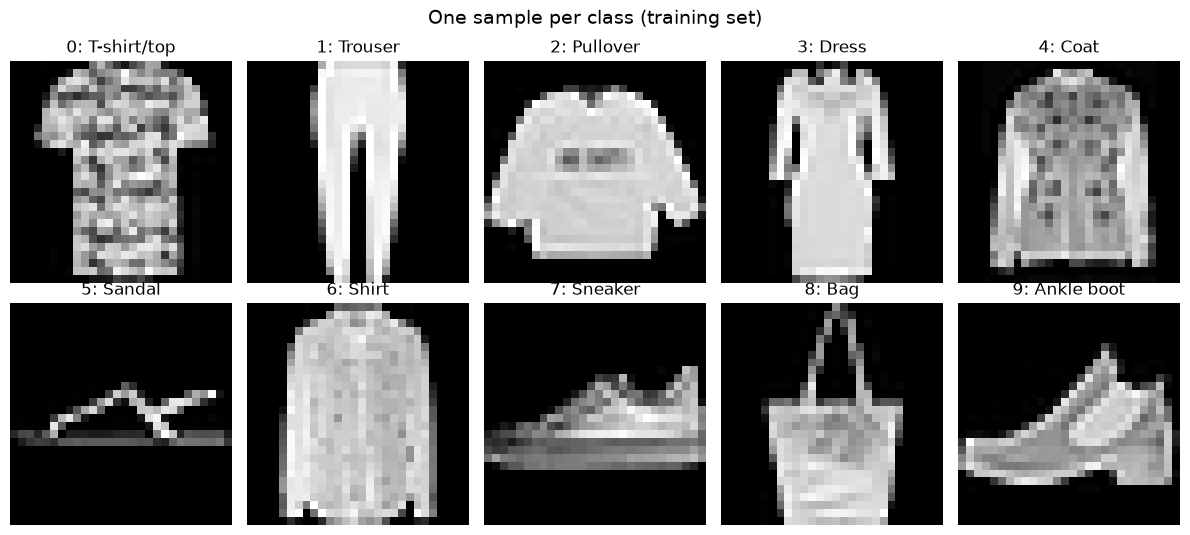

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for cls, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == cls)[0][0]           # first image of this class
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"{cls}: {CLASS_NAMES[cls]}")
    ax.axis("off")
fig.suptitle("One sample per class (training set)", fontsize=14)
plt.tight_layout()
plt.show()

### 1.3 Class balance check
We count the images per class in both the training and test sets. A balanced dataset lets us use plain accuracy as a fair overall metric.


,class,train count,test count
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


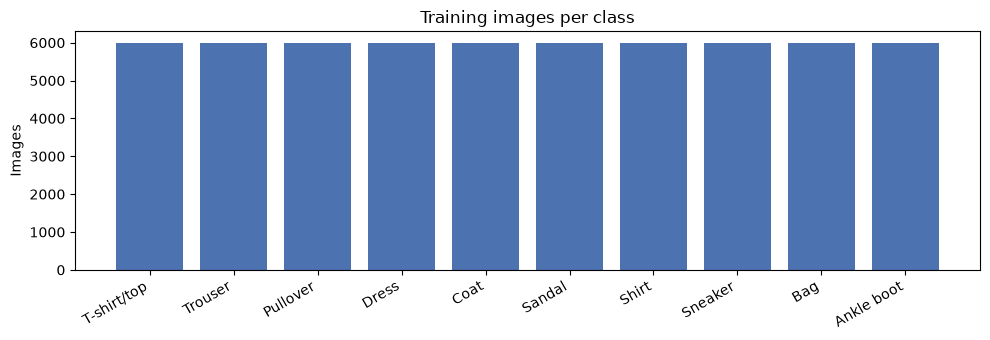

Perfectly balanced: True


In [5]:
balance = pd.DataFrame({
    "class": CLASS_NAMES,
    "train count": np.bincount(y_train_full, minlength=10),
    "test count": np.bincount(y_test, minlength=10),
})
display(balance)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(CLASS_NAMES, balance["train count"], color="#4C72B0")
ax.set_ylabel("Images")
ax.set_title("Training images per class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

is_balanced = balance["train count"].nunique() == 1 and balance["test count"].nunique() == 1
print("Perfectly balanced:", is_balanced)

Every class has exactly **6,000 training** and **1,000 test** images so the dataset is perfectly balanced. That means plain accuracy is a fair headline metric and we don't need class weighting or resampling.

### 1.4 Scaling and flattening with the validation split

* **Scaling** means dividing by 255 so every pixel lies in [0, 1].
* **Flattening** is straightforward because the CSV already stores each image as a row of 784 values so each sample is already a 784-feature vector. (Images would otherwise be reshaped from 28 × 28 to 784.)
* **Validation split** means holding out 10,000 of the 60,000 training images (stratified so each class still has an equal share). The test set stays untouched until Task 3.

In [6]:
# Scale to [0, 1]
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Flatten (no-op for CSV data, shown explicitly for clarity)
X_train_full = X_train_full.reshape(len(X_train_full), -1)
X_test = X_test.reshape(len(X_test), -1)

# Stratified train / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=10_000,
    stratify=y_train_full, random_state=SEED)

print(f"Pixel range after scaling: {X_train.min():.1f} to {X_train.max():.1f}\n")
print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")

Pixel range after scaling: 0.0 to 1.0

X_train: (50000, 784)   y_train: (50000,)
X_val:   (10000, 784)   y_val:   (10000,)
X_test:  (10000, 784)   y_test:  (10000,)


**Final shapes are** training `(50000, 784)`, validation `(10000, 784)` and test `(10000, 784)`.

**Why scale pixels?** Scaling inputs to a small consistent range (0 to 1 instead of 0 to 255) keeps the weighted sums and gradients at a reasonable size so gradient descent converges faster and more stably instead of being dominated by large raw values.